### Forecast data

In [11]:
import numpy as np
import matplotlib.pyplot as plt
import solarpy
import pvlib
import pandas as pd

In [12]:
from pathlib import Path
import sys

project_root = Path.cwd()
if project_root.name == "notebooks":
    project_root = project_root.parent

sys.path.insert(0, str(project_root))

from scripts.functions import get_dmi_ghi, resample_dmi_ghi_hourly, get_forecast_data 

In [14]:
#Get raw DMI measurements 
dmi_data = get_dmi_ghi(start="2026-11-09", end="2026-11-11")

#Resample to hourly measurements
hourly_dmi = resample_dmi_ghi_hourly(dmi_data)

#Get forecasts and match with measurements
forecast_data = get_forecast_data(hourly_dmi, start="2026-11-09", end="2026-11-11")

In [15]:
dmi_data.info()

<class 'pandas.DataFrame'>
DatetimeIndex: 281 entries, 2026-11-09 00:00:00+00:00 to 2026-11-11 00:00:00+00:00
Data columns (total 1 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   ghi     281 non-null    float64
dtypes: float64(1)
memory usage: 4.4 KB


In [16]:
forecast_data.keys()

dict_keys(['dmi_harmonie_arome_europe', 'metno_nordic', 'ecmwf_ifs025', 'ecmwf_aifs025_single', 'gfs_global', 'ecmwf_ifs', 'dmi_seamless', 'gfs_seamless'])

## Filter night away using solpos

Find solar position, in order to filter night data points away

In [ ]:
timestamps = pd.DatetimeIndex(forecast_data.index.get_level_values(0))

solpos = pvlib.solarposition.get_solarposition(
    timestamps,
    latitude=56.93,
    longitude=8.6412,
    method="nrel_numpy",
)

solhøjde = solpos["apparent_elevation"]

df_forecast_day = forecast_data.loc[solhøjde.to_numpy() > 0]
df_forecast_day.info()


# Calculate solar position for forecast valid times
timestamps = pd.DatetimeIndex(pd.concat(forecast_data.values())["valid_time"].unique())

solpos = pvlib.solarposition.get_solarposition(
    timestamps,
    latitude=56.93,
    longitude=8.6412,
    method="nrel_numpy",
)

solhøjde = solpos["apparent_elevation"]

# Keep only daylight hours
daylight_times = timestamps[solhøjde.to_numpy() > 0]

forecast_day = {
    model: df[df["valid_time"].isin(daylight_times)].copy()
    for model, df in forecast_data.items()
}


AttributeError: 'dict' object has no attribute 'index'

It is easiest to work with one forecast model at a time. To avoid having the rows be specified by a multi-index, we can use ``.unstack()`` function, to unstack the index, such that the index becomes just the time and the lead time becomes the columns.

In [ ]:
dmi_harmonie_arome_europe = df_forecast_day["dmi_harmonie_arome_europe"].unstack()

KeyError: 'dmi_harmonie_arome_europe'

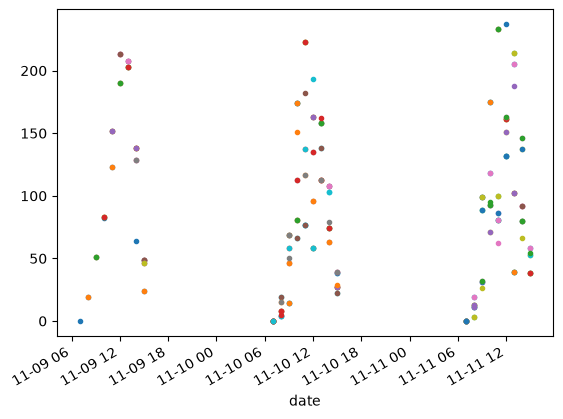

In [ ]:
fig, ax = plt.subplots()
dmi_harmonie_arome_europe.plot(ax=ax, lw=0, marker=".")
plt.legend().remove()
plt.show()

In [ ]:

metno_nordic = df_forecast_day["metno_nordic"].unstack()
ecmwf_ifs025 = df_forecast_day["ecmwf_ifs025"].unstack()
ecmwf_aifs025_single = df_forecast_day["ecmwf_aifs025_single"].unstack()
gfs_global = df_forecast_day["gfs_global"].unstack()
ecmwf_ifs = df_forecast_day["ecmwf_ifs"].unstack()
dmi_seamless = df_forecast_day["dmi_seamless"].unstack()
gfs_seamless = df_forecast_day["gfs_seamless"].unstack()